# BDB 2027 — Does an OL's movement foreshadow his absence? (tracking deep dive)

The previous notebook showed that pre-draft traits barely predict absences once draft pick is known. This notebook switches to the **game tracking data**: how a lineman actually moves, game by game and rep by rep. The question is whether changes in that movement come before he misses time.

The key design choice: almost every feature is compared to **the player's own baseline**. A rookie guard being slower than an All-Pro tackle tells you nothing. The same guard being slower than *he* usually is might. Within-player comparisons also mostly sidestep the draft-pick confound, because pick doesn't change week to week.

| § | Angle | Question |
|---|---|---|
| 3 | Movement signature | Which per-rep mechanics can we measure reliably (get-off, burst, braking, set depth, L/R lateral speed)? |
| 4 | Personal baselines | How much does each player vary from game to game? |
| 5 | **Pre-absence event study** | In the 1–5 games before an absence, does his movement drift away from his baseline? |
| 6 | **Within-game exits** | In the reps just before he leaves a game, does movement degrade beyond normal late-game fatigue? |
| 7 | **Return-to-play** | When he comes back, is he diminished? This is also a **test of the proxy**: injured players should come back slower, and benched players shouldn't. |
| 8 | In-game L/R asymmetry | Does favoring one side grow before an absence? Does Combine asymmetry carry into games? |
| 9 | **Combine context** | How close to his Combine ceiling does he operate? Does load hurt low-capacity players more? |
| 10 | Load, revisited | Acute:chronic ratios built from movement intensity (hard decels), not just snaps |
| 11 | Single-feature screening | How well does each game-level feature alone separate "absent next game" from "plays next game"? |
| 12 | Synthesis | Which signals are consistent across angles, and what model they support |

Everything is descriptive. Intervals come from bootstraps **clustered by player**, because games from the same player aren't independent.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 120); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

CANDIDATES = [Path("data"), Path("../data"), Path("data/raw"), Path("/kaggle/input/nfl-big-data-bowl-2027")]
DATA_DIR = next((p for p in CANDIDATES if (p / "games.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("games.csv not found in: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
print("Data dir:", DATA_DIR.resolve())
NULLS = ["NA", "NULL", "null", "None", ""]

def find_csv(stem):
    f = DATA_DIR / f"{stem}.csv"
    if not f.exists(): raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return f

def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

# ---- knobs ---------------------------------------------------------------
SEASONS       = [2023, 2024, 2025]
REGULAR_SNAPS = 30      # ≥ this many snaps in a game = established regular
EXIT_FRAC     = 0.5     # in-game exit: snaps < 50% of trailing median
LONG_ABSENCE  = 4       # spell length (games) counted as long / IR-like
REP_WINDOW_S  = 3.0     # seconds after snap used for per-rep mechanics
MIN_REPS_GAME = 8       # need ≥ this many tracked reps for a game-level feature
BASE_K, BASE_MIN = 6, 3 # personal baseline: previous up-to-6 played games, ≥3 required
LAGS          = 5       # event study: games before the absence
HI_DECEL      = 3.0     # yd/s² hard-braking threshold
N_BOOT        = 1000
RNG           = np.random.default_rng(27)
CACHES        = [Path("ol_tracking_cache.parquet")]   # reuse caches from earlier notebooks if present
NEW_CACHE     = Path("ol_tracking_cache_v2.parquet")
SNAP          = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
# --------------------------------------------------------------------------

def cluster_boot_mean(values, clusters, n=N_BOOT):
    # Mean with a bootstrap CI that resamples whole players (clusters)
    d = pd.DataFrame({"v": values, "c": clusters}).dropna()
    if d.empty: return np.nan, np.nan, np.nan, 0
    sums = d.groupby("c")["v"].agg(["sum", "size"])
    ids = sums.index.to_numpy(); k = len(ids)
    if k < 3: return d["v"].mean(), np.nan, np.nan, len(d)
    draws = RNG.integers(0, k, (n, k))
    s, c = sums["sum"].to_numpy(), sums["size"].to_numpy()
    bs = s[draws].sum(1) / c[draws].sum(1)
    return d["v"].mean(), *np.percentile(bs, [2.5, 97.5]), len(d)

def auc(y, x):
    m = pd.notna(x) & pd.notna(y); y, x = np.asarray(y[m]).astype(int), np.asarray(x[m])
    if y.sum() == 0 or y.sum() == len(y): return np.nan
    r = stats.rankdata(x); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def cluster_boot_auc(y, x, clusters, n=N_BOOT // 2):
    d = pd.DataFrame({"y": y, "x": x, "c": clusters}).dropna()
    a = auc(d["y"], d["x"])
    groups = [g for _, g in d.groupby("c")]; k = len(groups)
    if k < 5 or np.isnan(a): return a, np.nan, np.nan
    bs = []
    for _ in range(n):
        s = pd.concat([groups[i] for i in RNG.integers(0, k, k)])
        bs.append(auc(s["y"], s["x"]))
    return a, *np.nanpercentile(bs, [2.5, 97.5])

Data dir: C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


## 1. Roster, play context and the player-game panel (same outcome definitions as the previous notebook)

In [2]:
players = pd.read_csv(find_csv("players"), na_values=NULLS)
combine = pd.read_csv(find_csv("combine_results"), na_values=NULLS)
games   = pd.read_csv(find_csv("games"), na_values=NULLS)
pp      = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

prof = players.merge(combine.drop(columns=[c for c in combine if c in players and c != "nfl_id"]), on="nfl_id", how="left")
NAME = pick(prof, ["display_name", "player_name", "full_name", "name"])
NFL_POS, CMB_POS = pick(prof, ["nfl_position", "position"]), pick(prof, ["combine_position"])
DRAFT_YR = pick(prof, ["draft_year"], required=True)
PICK = pick(prof, ["draft_pick", "draft_overall_pick", "overall_pick", "draft_number"])
LUP  = pick(pp, ["lined_up_position", "position_at_snap"], required=True)
TEAM = pick(pp, ["team_abbr", "club", "team"], required=True)
DIR  = pick(pp, ["play_direction"])
QTR  = pick(pp, ["quarter"])
HOME, AWAY = pick(games, ["home_team_abbr"]), pick(games, ["visitor_team_abbr", "away_team_abbr"])
PASS_COLS = [c for c in [pick(pp, ["is_dropback"]), pick(pp, ["play_type", "pff_run_pass"]), pick(pp, ["pass_result"])] if c]

def to_group(p):
    if pd.isna(p): return np.nan
    p = str(p).upper().strip()
    if p in {"C", "OC"}: return "C"
    if p in {"G", "OG", "LG", "RG"}: return "G"
    if p in {"T", "OT", "LT", "RT"}: return "T"
    return np.nan

OL_LABELS = {"OL", "OT", "OG", "IOL", "C", "G", "T", "LT", "RT", "LG", "RG", "OC"}
is_ol = pd.Series(False, index=prof.index)
for c in [CMB_POS, NFL_POS]:
    if c: is_ol |= prof[c].astype(str).str.upper().isin(OL_LABELS)
ol = prof[is_ol].copy()

gcols = ["game_id", "season", "week"] + [c for c in ["season_type"] if c in games]
ol_pp = pp[pp["nfl_id"].isin(ol["nfl_id"])].merge(games[gcols], on="game_id", how="left")
if "season_type" in ol_pp: ol_pp = ol_pp[ol_pp["season_type"].fillna("REG") == "REG"]
ol_pp["spot"] = ol_pp[LUP].map(to_group)
pos = ol_pp.dropna(subset=["spot"]).groupby("nfl_id")["spot"].agg(lambda s: s.mode().iloc[0])
ol["pos_group"] = ol["nfl_id"].map(pos)

def infer_pass(df):
    s = pd.Series(np.nan, index=df.index)
    for c in PASS_COLS:
        v = df[c]
        if c.lower() == "is_dropback": s = s.fillna(v.astype(str).str.lower().isin(["true", "1"]).astype(float).where(v.notna()))
        elif c.lower() == "pass_result": s = s.fillna(v.notna().astype(float))
        else:
            lv = v.astype(str).str.lower()
            s = s.fillna(pd.Series(np.select([lv.str.contains("pass"), lv.str.contains("run|rush")], [1.0, 0.0], np.nan), index=df.index))
    return s
ol_pp["is_pass"] = infer_pass(ol_pp)

# ---- panel (team schedule expansion, stints, events) ----
sched = pd.concat([games[["game_id", "season", "week", HOME]].rename(columns={HOME: "team"}),
                   games[["game_id", "season", "week", AWAY]].rename(columns={AWAY: "team"})])
if "season_type" in games: sched = sched[sched["game_id"].isin(games.loc[games["season_type"] == "REG", "game_id"])]
sched = sched.sort_values(["team", "season", "week"])
sched["team_game_no"] = sched.groupby(["team", "season"]).cumcount() + 1

pg = ol_pp.groupby(["nfl_id", "game_id", "season", "week"]).agg(snaps=("play_id", "size"), team=(TEAM, "first")).reset_index()
stint = (pg.merge(sched[["game_id", "team", "team_game_no"]], on=["game_id", "team"])
           .groupby(["nfl_id", "season", "team"])["team_game_no"].agg(first_g="min", last_g="max").reset_index())
stint["multi"] = stint.groupby(["nfl_id", "season"])["team"].transform("nunique") > 1
panel = stint.merge(sched, on=["season", "team"])
panel = panel[(panel["team_game_no"] >= panel["first_g"]) & ((panel["team_game_no"] <= panel["last_g"]) | ~panel["multi"])]
panel = panel.merge(pg[["nfl_id", "game_id", "snaps"]], on=["nfl_id", "game_id"], how="left").fillna({"snaps": 0})
panel = panel.sort_values(["nfl_id", "season", "team", "team_game_no"]).reset_index(drop=True)
G = panel.groupby(["nfl_id", "season", "team"])
panel["played"] = panel["snaps"] > 0
panel["established"] = G["snaps"].transform(lambda s: (s >= REGULAR_SNAPS).shift(fill_value=False).cummax())
panel["prev_played"] = G["played"].shift(fill_value=False)
panel["trail_med"] = G["snaps"].transform(lambda s: s.where(s >= REGULAR_SNAPS).shift().expanding().median())
panel["absence_start"] = panel["established"] & panel["prev_played"] & ~panel["played"]
panel["spell_id"] = (panel["played"] != G["played"].shift()).cumsum()
panel["spell_len"] = panel["spell_id"].map(panel[~panel["played"]].groupby("spell_id").size()).where(panel["absence_start"])
panel["long_absence_start"] = panel["absence_start"] & (panel["spell_len"] >= LONG_ABSENCE)
panel["exit"] = panel["established"] & panel["played"] & panel["trail_med"].notna() & (panel["snaps"] < EXIT_FRAC * panel["trail_med"])
panel["next_absence"] = G["absence_start"].shift(-1, fill_value=False)
panel["next_long_absence"] = G["long_absence_start"].shift(-1, fill_value=False)
panel["exit_then_miss"] = panel["exit"] & panel["next_absence"]
print(f"panel {len(panel):,} | events:", {k: int(panel[k].sum()) for k in ["absence_start", "long_absence_start", "exit", "exit_then_miss"]})

panel 2,277 | events: {'absence_start': 135, 'long_absence_start': 38, 'exit': 133, 'exit_then_miss': 52}


## 2. Load OL tracking

This reuses a cache from an earlier notebook if it has the needed columns. Otherwise it scans the season files once (chunked) and writes a new cache.

In [3]:
NEED = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "event"]
trk = None
for c in CACHES + [NEW_CACHE]:
    if c.exists():
        t = pd.read_parquet(c)
        if set(NEED) <= set(t.columns): trk = t; print("using cache", c); break
if trk is None:
    ids, parts = set(ol["nfl_id"]), []
    for season in SEASONS:
        f = find_csv(f"game_tracking_{season}")
        cols = [c for c in NEED + ["a"] if c in pd.read_csv(f, nrows=1).columns]
        for ch in pd.read_csv(f, usecols=cols, chunksize=2_000_000, na_values=NULLS):
            parts.append(ch[ch["nfl_id"].isin(ids)])
        print(season, "scanned")
    trk = pd.concat(parts, ignore_index=True); trk.to_parquet(NEW_CACHE, index=False)
trk = trk[[c for c in NEED + ["a"] if c in trk]].copy()
# keep only reps where he lined up on the OL
reps_ctx = ol_pp.loc[ol_pp["spot"].notna(), ["game_id", "play_id", "nfl_id", "spot", "is_pass"] + [c for c in [DIR, QTR] if c]]
trk = trk.merge(reps_ctx[["game_id", "play_id", "nfl_id"]], on=["game_id", "play_id", "nfl_id"])
print(f"OL tracking rows: {len(trk):,}")

using cache ol_tracking_cache.parquet
OL tracking rows: 6,100,356


## 3. Movement signature: per-rep mechanics

Each rep is standardized so the offense moves toward +x. Depth and lateral movement are measured from his position at the snap. Lateral sign is fixed in this frame: **+lat = offense's left**. That gives a consistent left/right for the asymmetry angle, even without knowing LT vs RT.

| feature | definition | "worse" direction |
|---|---|---|
| `get_off` | seconds from snap until he has moved 0.5 yd | higher |
| `t_1yd` | seconds to 1 yd of displacement (first-step burst) | higher |
| `peak_speed` | max speed in the first `REP_WINDOW_S` s | lower |
| `peak_accel` | max speed gain rate in the first 1.5 s | lower |
| `peak_decel` | max braking rate (speed loss) in the window | ambiguous: lower = less capacity, but braking is also a loading event |
| `set_depth` | deepest retreat in the first 2 s (pass reps) | context |
| `lat_left_pk` / `lat_right_pk` | fastest lateral speed toward each side | used for asymmetry |
| `dist` | yards traveled in the window | load |

In [4]:
k = ["game_id", "play_id", "nfl_id"]
trk["time"] = pd.to_datetime(trk["time"], errors="coerce")
trk = trk.sort_values(k + ["time"])
snap_t = trk.loc[trk["event"].isin(SNAP)].groupby(k)["time"].min().rename("snap_time")
f = trk.merge(snap_t, left_on=k, right_index=True)
f["t"] = (f["time"] - f["snap_time"]).dt.total_seconds()
f = f[(f["t"] >= 0) & (f["t"] <= REP_WINDOW_S)].merge(reps_ctx, on=k, how="left")
sgn = np.where(f[DIR] == "left", -1, 1) if DIR else 1
g = f.groupby(k)
x0, y0 = g["x"].transform("first"), g["y"].transform("first")
f["depth"] = sgn * (f["x"] - x0); f["lat"] = sgn * (f["y"] - y0)
f["disp"] = np.hypot(f["depth"], f["lat"])
dt = g["t"].diff()
f["step"] = np.hypot(g["x"].diff(), g["y"].diff()).fillna(0)
f["dv"] = g["s"].diff() / dt
f["vlat"] = f.groupby(k)["lat"].diff() / dt
f.loc[dt > 0.25, ["dv", "vlat"]] = np.nan          # ignore tracking gaps

def first_t(cond):
    return f["t"].where(cond).groupby([f[c] for c in k]).min()

rep = pd.DataFrame({
    "get_off": first_t(f["disp"] >= 0.5), "t_1yd": first_t(f["disp"] >= 1.0),
    "peak_speed": g["s"].max(), "dist": f.groupby(k)["step"].sum(),
    "peak_accel": f["dv"].where(f["t"] <= 1.5).groupby([f[c] for c in k]).max(),
    "peak_decel": (-f["dv"]).groupby([f[c] for c in k]).max(),
    "set_depth": (-f["depth"].where(f["t"] <= 2.0)).groupby([f[c] for c in k]).max().clip(lower=0),
    "lat_left_pk": f["vlat"].clip(lower=0).groupby([f[c] for c in k]).max(),
    "lat_right_pk": (-f["vlat"]).clip(lower=0).groupby([f[c] for c in k]).max(),
    "n_frames": g.size(),
}).reset_index().merge(reps_ctx, on=k, how="left")
rep = rep[rep["n_frames"] >= 10]
rep["rep_no"] = rep.sort_values("play_id").groupby(["game_id", "nfl_id"]).cumcount()
rep["n_reps_game"] = rep.groupby(["game_id", "nfl_id"])["play_id"].transform("size")
rep["late"] = (rep[QTR] >= 3) if QTR and rep[QTR].nunique() > 1 else rep["rep_no"] >= rep["n_reps_game"] / 2
MECH = ["get_off", "t_1yd", "peak_speed", "peak_accel", "peak_decel", "set_depth", "dist"]
WORSE_UP = {"get_off": True, "t_1yd": True, "peak_speed": False, "peak_accel": False, "peak_decel": False, "set_depth": False, "dist": False}
print(f"reps with mechanics: {len(rep):,} | players: {rep['nfl_id'].nunique()}")
display(rep[MECH + ["lat_left_pk", "lat_right_pk"]].describe(percentiles=[.05, .5, .95]).round(2))

reps with mechanics: 85,741 | players: 89


,get_off,t_1yd,peak_speed,peak_accel,peak_decel,set_depth,dist,lat_left_pk,lat_right_pk
count,84913.00,84076.00,85741.00,85741.00,85741.00,85741.00,85741.00,85741.00,85741.00
mean,0.64,0.95,2.87,3.21,2.13,1.80,5.85,1.34,1.27
std,0.25,0.35,0.98,1.06,1.14,1.74,2.29,1.22,1.20
min,0.10,0.20,0.00,-0.10,-1.10,0.00,0.05,0.00,0.00
5%,0.40,0.60,1.43,1.70,0.50,0.00,2.59,0.00,0.00
50%,0.60,0.90,2.80,3.10,2.00,1.54,5.61,1.10,1.00
95%,1.10,1.60,4.59,4.90,4.20,4.83,10.02,3.80,3.80
max,3.00,3.00,7.58,53.80,16.90,7.28,18.71,19.00,9.80


In [5]:
# Reliability check: how stable is each mechanic within a player? (split-half by odd/even reps, player level)
rel = []
for m in MECH:
    a = rep[rep["rep_no"] % 2 == 0].groupby("nfl_id")[m].median()
    b = rep[rep["rep_no"] % 2 == 1].groupby("nfl_id")[m].median()
    j = pd.concat([a, b], axis=1).dropna()
    r = j.corr(method="spearman").iloc[0, 1] if len(j) > 5 else np.nan
    rel.append({"feature": m, "split_half_rho": r, "spearman_brown": 2 * r / (1 + r) if pd.notna(r) else np.nan, "players": len(j)})
rel = pd.DataFrame(rel).round(3)
display(rel)
print("Features with reliability < ~0.6 are mostly noise at the player level; treat their results cautiously.")

,feature,split_half_rho,spearman_brown,players
0,get_off,0.792,0.884,88
1,t_1yd,0.671,0.803,88
2,peak_speed,0.724,0.840,88
3,peak_accel,0.849,0.918,88
4,peak_decel,0.483,0.651,88
5,set_depth,0.756,0.861,88
6,dist,0.736,0.848,88


Features with reliability < ~0.6 are mostly noise at the player level; treat their results cautiously.


## 4. Game-level features and personal baselines

Reps are aggregated per player-game (medians for mechanics, sums for load), plus two within-game measures:
- **Fade**: late-game median minus early-game median (second half vs. first half, by quarter if available).
- **L/R asymmetry**: (left − right lateral peak speed) ÷ mean. In this standardized frame it is a *signed* asymmetry, so a growing magnitude means he's favoring one side more.

Then each game value is turned into a **personal z-score** against his previous up to `BASE_K` played games: z = (value − baseline mean) ÷ baseline SD.

In [6]:
gl = rep.groupby(["game_id", "nfl_id"]).agg(
    trk_reps=("play_id", "size"), dist_total=("dist", "sum"),
    hard_decels=("peak_decel", lambda s: (s >= HI_DECEL).sum()),
    **{m: (m, "median") for m in MECH},
    lat_left=("lat_left_pk", lambda s: s[s > 0.5].median()), lat_right=("lat_right_pk", lambda s: s[s > 0.5].median()))
for m in ["get_off", "peak_speed", "peak_accel"]:
    e = rep[~rep["late"]].groupby(["game_id", "nfl_id"])[m].median()
    l = rep[rep["late"]].groupby(["game_id", "nfl_id"])[m].median()
    gl[f"fade_{m}"] = l - e
gl["lr_asym"] = (gl["lat_left"] - gl["lat_right"]) / ((gl["lat_left"] + gl["lat_right"]) / 2)
gl["abs_lr_asym"] = gl["lr_asym"].abs()
gl = gl[gl["trk_reps"] >= MIN_REPS_GAME].reset_index()

panel = panel.drop(columns=[c for c in gl if c in panel and c not in ["game_id", "nfl_id"]]).merge(gl, on=["game_id", "nfl_id"], how="left")
FEATS = MECH + ["fade_get_off", "fade_peak_speed", "fade_peak_accel", "abs_lr_asym", "hard_decels", "dist_total", "trk_reps"]

# Personal baseline z-scores across his career (previous played+tracked games, any season)
panel = panel.sort_values(["nfl_id", "season", "team_game_no"]).reset_index(drop=True)
tracked = panel["trk_reps"].notna()
for m in FEATS:
    v = panel[m].where(tracked)
    gp = v.groupby(panel["nfl_id"])
    mu = gp.transform(lambda s: s.shift().rolling(BASE_K, min_periods=BASE_MIN).mean())
    sd = gp.transform(lambda s: s.shift().rolling(BASE_K, min_periods=BASE_MIN).std())
    floor = v.groupby(panel["nfl_id"]).transform("std") * 0.25            # avoid exploding z when baseline is tiny
    panel[f"z_{m}"] = (v - mu) / np.maximum(sd, floor.fillna(sd))
ZF = [f"z_{m}" for m in FEATS]
cov = tracked[panel["played"]].mean()
print(f"Played games with ≥{MIN_REPS_GAME} tracked reps: {cov:.0%} | with a baseline z: {panel['z_get_off'].notna().sum():,}")

# Between- vs within-player variance: how much of each feature is 'who he is' vs 'how he's doing this week'?
icc = []
for m in FEATS:
    d = panel.loc[tracked, ["nfl_id", m]].dropna()
    if d["nfl_id"].nunique() < 5: continue
    between = d.groupby("nfl_id")[m].mean().var(); within = d.groupby("nfl_id")[m].var().mean()
    icc.append({"feature": m, "share_between_player": between / (between + within)})
display(pd.DataFrame(icc).round(2).sort_values("share_between_player"))

Played games with ≥8 tracked reps: 88% | with a baseline z: 1,109


,feature,share_between_player
8,fade_peak_speed,0.24
5,set_depth,0.27
9,fade_peak_accel,0.28
4,peak_decel,0.29
10,abs_lr_asym,0.31
7,fade_get_off,0.32
11,hard_decels,0.43
0,get_off,0.48
13,trk_reps,0.51
2,peak_speed,0.52


## 5. Pre-absence event study: does movement drift before he misses time?

For every absence start, take his last `LAGS` played games beforehand (lag 1 = the game right before he missed). Then average his personal z-scores at each lag.

**Control:** the same lags before games he *did* play, drawn from established regulars. That shows what a normal stretch looks like, because z-scores don't average exactly to 0 due to drift and season trends.

A real precursor shows the event curve separating from the control as lag → 1, ideally more strongly for **long absences** and **exit → miss**, which are the most injury-like.

For **exit → miss**, lag 1 *is* the exit game, so count-based features (`trk_reps`, `hard_decels`) drop there by construction. Read only the per-rep mechanics at that lag.

In [7]:
played_tracked = panel[panel["played"] & panel["trk_reps"].notna()].copy()
played_tracked["pg_idx"] = played_tracked.groupby("nfl_id").cumcount()
idx_by_game = played_tracked.set_index(["nfl_id", "game_id"])["pg_idx"]

def anchor_rows(event_col):
    # For each event game, the last played game before it is lag 1
    ev = panel[panel[event_col]].copy()
    prev = panel[panel["played"] & panel["trk_reps"].notna()][["nfl_id", "season", "team_game_no", "game_id"]]
    out = []
    for _, r in ev.iterrows():
        p = prev[(prev["nfl_id"] == r["nfl_id"]) & ((prev["season"] < r["season"]) |
                ((prev["season"] == r["season"]) & (prev["team_game_no"] < r["team_game_no"])))]
        if len(p): out.append((r["nfl_id"], p.iloc[-1]["game_id"]))
    return out

def event_curve(anchors, label):
    rows = []
    for nid, gid in anchors:
        if (nid, gid) not in idx_by_game.index: continue
        i0 = idx_by_game.loc[(nid, gid)]
        sub = played_tracked[(played_tracked["nfl_id"] == nid) & (played_tracked["pg_idx"].between(i0 - LAGS + 1, i0))]
        rows.append(sub.assign(lag=i0 - sub["pg_idx"] + 1, event_id=f"{nid}_{gid}"))
    return pd.concat(rows, ignore_index=True).assign(set=label) if rows else pd.DataFrame()

ev_sets = {"absence": anchor_rows("absence_start"), "long absence": anchor_rows("long_absence_start")}
# exit→miss: anchor is the exit game itself (he played it), so use those games directly
ev_sets["exit→miss"] = list(panel.loc[panel["exit_then_miss"] & panel["trk_reps"].notna(), ["nfl_id", "game_id"]].itertuples(index=False, name=None))
# control: random played games by established players that were followed by another played game
ctrl_pool = panel[panel["played"] & panel["established"] & panel["trk_reps"].notna() & ~panel["next_absence"]]
n_ctrl = min(len(ctrl_pool), 4 * max(len(v) for v in ev_sets.values()) + 50)
ev_sets["control"] = list(ctrl_pool.sample(n_ctrl, random_state=27)[["nfl_id", "game_id"]].itertuples(index=False, name=None))
curves = pd.concat([event_curve(a, s) for s, a in ev_sets.items()], ignore_index=True)
print({s: len(a) for s, a in ev_sets.items()})

{'absence': 135, 'long absence': 38, 'exit→miss': 26, 'control': 590}


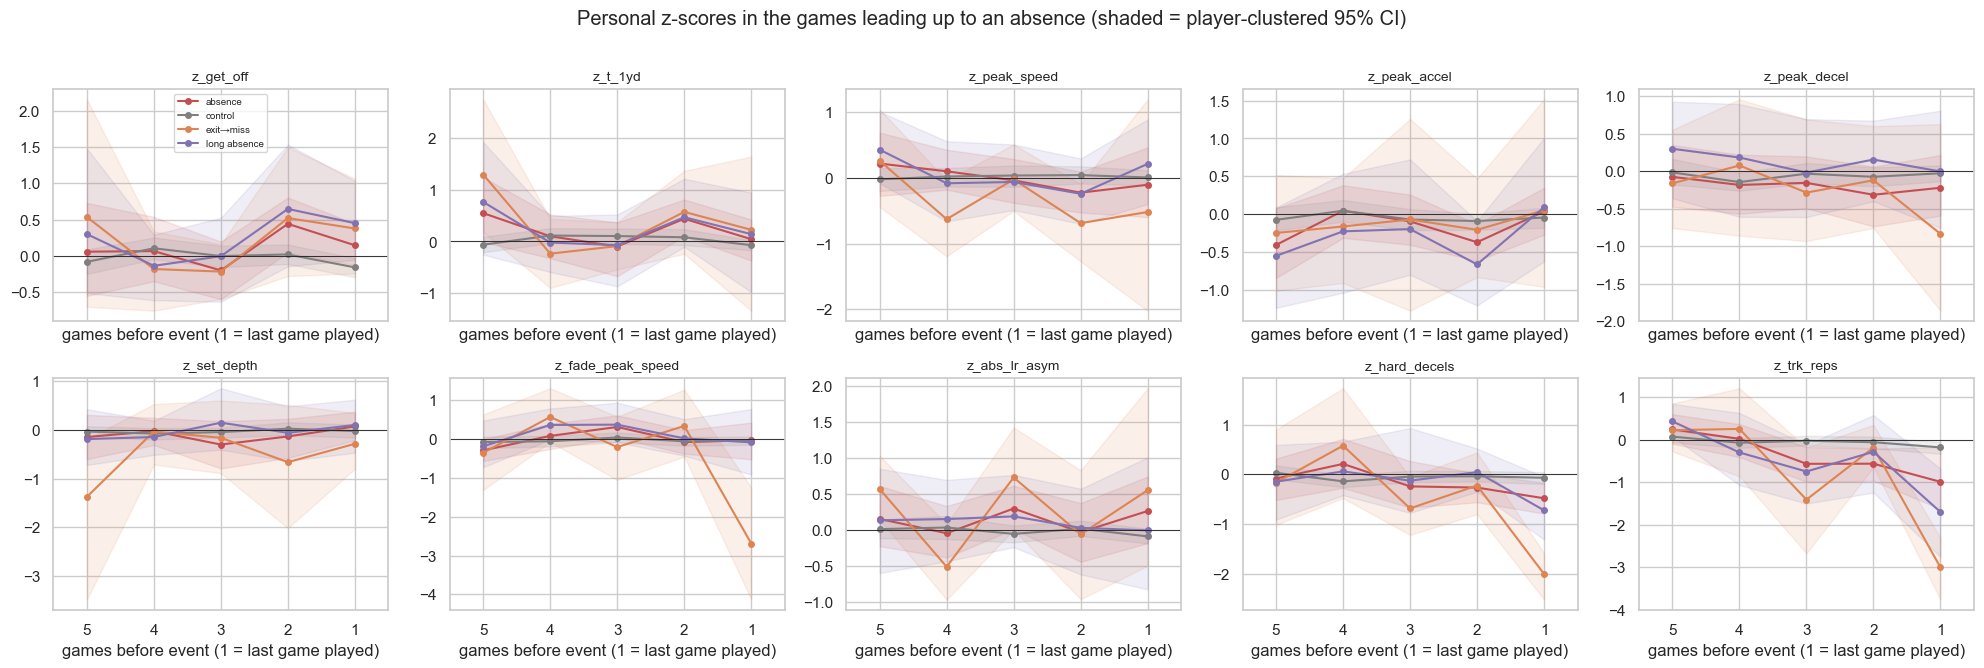

set,absence,control,exit→miss,long absence,absence − control,exit→miss − control,long absence − control
feature,,,,,,,
z_abs_lr_asym,0.27,-0.09,0.55,-0.00,0.35,0.64,0.08
z_fade_peak_speed,-0.03,-0.04,-2.69,-0.08,0.01,-2.65,-0.04
z_get_off,0.14,-0.16,0.38,0.45,0.31,0.54,0.61
z_hard_decels,-0.48,-0.07,-2.00,-0.72,-0.41,-1.93,-0.65
z_peak_accel,0.04,-0.04,0.05,0.09,0.08,0.10,0.14
z_peak_decel,-0.22,-0.03,-0.84,-0.00,-0.19,-0.81,0.02
z_peak_speed,-0.11,0.01,-0.52,0.21,-0.11,-0.53,0.21
z_set_depth,0.07,-0.02,-0.28,0.10,0.09,-0.26,0.12
z_t_1yd,0.04,-0.07,0.22,0.14,0.12,0.30,0.21


In [8]:
SHOW = ["z_get_off", "z_t_1yd", "z_peak_speed", "z_peak_accel", "z_peak_decel", "z_set_depth",
        "z_fade_peak_speed", "z_abs_lr_asym", "z_hard_decels", "z_trk_reps"]
SHOW = [c for c in SHOW if c in curves]
colors = {"absence": "#C44E52", "long absence": "#8172B2", "exit→miss": "#DD8452", "control": "#7F7F7F"}
ncols = 5; nrows = int(np.ceil(len(SHOW) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.3 * nrows), squeeze=False, sharex=True)
event_stats = []
for ax, zc in zip(axes.flat, SHOW):
    for s, d in curves.groupby("set"):
        pts = [(lag, *cluster_boot_mean(dd[zc], dd["nfl_id"])) for lag, dd in d.groupby("lag")]
        if not pts: continue
        lag, m, lo, hi, n = map(np.array, zip(*pts))
        ax.plot(lag, m, "o-", color=colors[s], label=s, ms=4)
        ax.fill_between(lag, lo, hi, color=colors[s], alpha=.12)
        for L, M, LO, HI, N in zip(lag, m, lo, hi, n):
            event_stats.append({"feature": zc, "set": s, "lag": L, "mean_z": M, "ci_lo": LO, "ci_hi": HI, "n": N})
    ax.axhline(0, color="k", lw=.6); ax.set_title(zc, fontsize=10)
    ax.set_xlabel("games before event (1 = last game played)")
axes.flat[0].legend(fontsize=7)
axes.flat[0].set_xlim(LAGS + .5, .5)   # time flows left → right toward the event (shared x)
for ax in axes.flat[len(SHOW):]: ax.axis("off")
fig.suptitle("Personal z-scores in the games leading up to an absence (shaded = player-clustered 95% CI)", y=1.01)
plt.tight_layout(); plt.show()

event_stats = pd.DataFrame(event_stats)
lag1 = event_stats[event_stats["lag"] == 1].pivot(index="feature", columns="set", values="mean_z")
for s in [c for c in lag1 if c != "control"]: lag1[f"{s} − control"] = lag1[s] - lag1["control"]
display(lag1.round(2))

## 6. Within-game exits: what do the last reps before he leaves look like?

For every in-game exit, his reps are aligned to the **end of his participation** (rep −1 = his last rep). Each rep is z-scored against his own career rep distribution. The control is the last reps of **full games he finished normally**, which captures ordinary late-game fatigue. Degradation in the exit curve beyond the control is the signal.

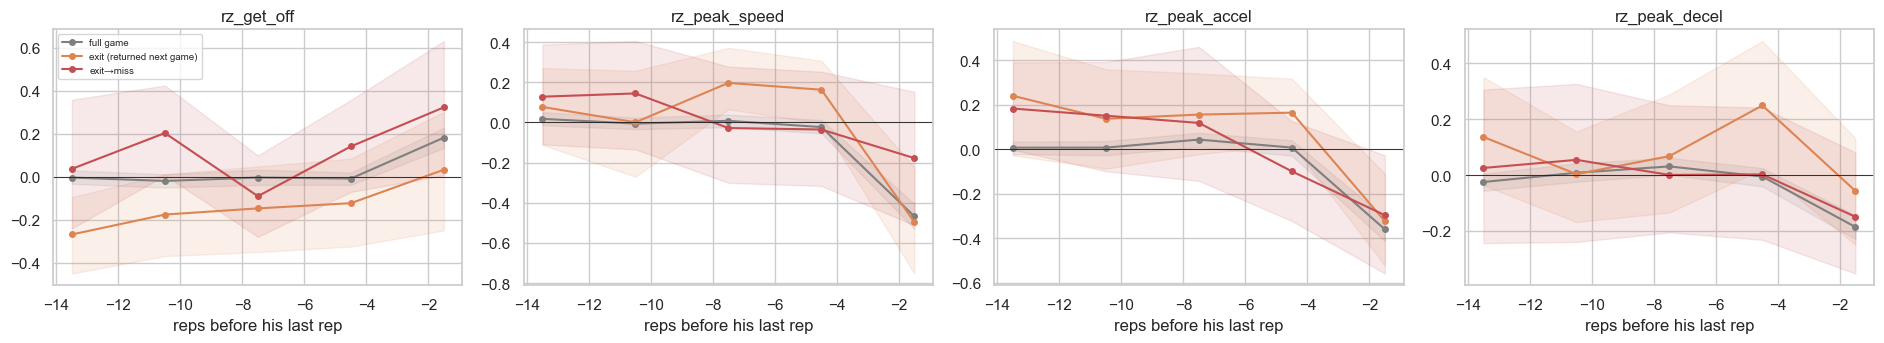

game_type,exit (returned next game),exit→miss,full game
feature,,,
rz_get_off,0.03,0.32,0.18
rz_peak_accel,-0.32,-0.30,-0.36
rz_peak_decel,-0.06,-0.15,-0.19
rz_peak_speed,-0.50,-0.18,-0.47


In [9]:
pstat = rep.groupby("nfl_id")[MECH].agg(["mean", "std"])
rz = rep.copy()
for m in MECH:
    rz[f"rz_{m}"] = (rz[m] - rz["nfl_id"].map(pstat[(m, "mean")])) / rz["nfl_id"].map(pstat[(m, "std")])
rz["from_end"] = rz["rep_no"] - rz["n_reps_game"]          # -1 = last rep
key = panel.set_index(["game_id", "nfl_id"])
rz = rz.join(key[["exit", "exit_then_miss", "established"]], on=["game_id", "nfl_id"])
rz["game_type"] = np.select([rz["exit_then_miss"] == True, rz["exit"] == True, rz["established"] == True],
                            ["exit→miss", "exit (returned next game)", "full game"], "other")
rz = rz[(rz["game_type"] != "other") & (rz["from_end"] >= -15)]

fig, axes = plt.subplots(1, 4, figsize=(19, 3.6), sharex=True)
exit_stats = []
for ax, m in zip(axes, ["rz_get_off", "rz_peak_speed", "rz_peak_accel", "rz_peak_decel"]):
    for gt, col in [("full game", "#7F7F7F"), ("exit (returned next game)", "#DD8452"), ("exit→miss", "#C44E52")]:
        d = rz[rz["game_type"] == gt].copy()
        d["bin"] = (d["from_end"] // 3) * 3          # bins of 3 reps
        pts = [(b, *cluster_boot_mean(dd[m], dd["nfl_id"])) for b, dd in d.groupby("bin")]
        if not pts: continue
        b, mm, lo, hi, n = map(np.array, zip(*pts))
        ax.plot(b + 1.5, mm, "o-", color=col, label=gt, ms=4); ax.fill_between(b + 1.5, lo, hi, color=col, alpha=.12)
        last = d[d["from_end"] >= -3]
        exit_stats.append({"feature": m, "game_type": gt, "last3_mean_z": last[m].mean(), "games": last["game_id"].nunique()})
    ax.axhline(0, color="k", lw=.6); ax.set_title(m); ax.set_xlabel("reps before his last rep")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
display(pd.DataFrame(exit_stats).pivot(index="feature", columns="game_type", values="last3_mean_z").round(2))

## 7. Return-to-play: is he diminished when he comes back?

This angle does double duty. If absences reflect injury, players should come back **slower or less explosive**, and more so after long spells. If they reflect benching, movement on return should look the same as before.

For each spell he returns from (same team), this compares the median of his **last 3 tracked games before** with his **first 3 after**, in units of his own between-game SD.

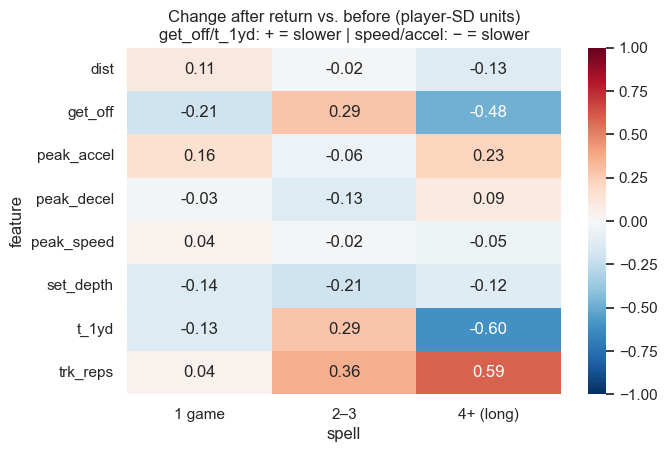

,spells with return
spell,
1 game,38
2–3,25
4+ (long),11


In [10]:
spells = panel[panel["absence_start"]][["nfl_id", "season", "team", "team_game_no", "spell_len"]].copy()
pt = panel[panel["played"] & panel["trk_reps"].notna()].sort_values(["nfl_id", "season", "team_game_no"])
psd = pt.groupby("nfl_id")[MECH + ["trk_reps"]].std()
rows = []
for _, s in spells.iterrows():
    mine = pt[pt["nfl_id"] == s["nfl_id"]]
    before = mine[(mine["season"] < s["season"]) | ((mine["season"] == s["season"]) & (mine["team_game_no"] < s["team_game_no"]))].tail(3)
    after = mine[(mine["season"] == s["season"]) & (mine["team"] == s["team"]) & (mine["team_game_no"] > s["team_game_no"])].head(3)
    if len(before) < 2 or len(after) < 2: continue
    r = {"nfl_id": s["nfl_id"], "spell_len": s["spell_len"]}
    for m in MECH + ["trk_reps"]:
        sd = psd.loc[s["nfl_id"], m]
        r[m] = (after[m].median() - before[m].median()) / sd if sd and sd > 0 else np.nan
    rows.append(r)
ret = pd.DataFrame(rows)
if len(ret):
    ret["spell"] = pd.cut(ret["spell_len"], [0, 1, LONG_ABSENCE - 1, 99], labels=["1 game", f"2–{LONG_ABSENCE-1}", f"{LONG_ABSENCE}+ (long)"])
    ret_tab = []
    for sp, d in ret.groupby("spell", observed=True):
        for m in MECH + ["trk_reps"]:
            mean, lo, hi, n = cluster_boot_mean(d[m], d["nfl_id"])
            ret_tab.append({"spell": sp, "feature": m, "change_sd": mean, "ci_lo": lo, "ci_hi": hi, "n": n})
    ret_tab = pd.DataFrame(ret_tab)
    piv = ret_tab.pivot(index="feature", columns="spell", values="change_sd")
    plt.figure(figsize=(7, 4.5))
    sns.heatmap(piv, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
    plt.title("Change after return vs. before (player-SD units)\nget_off/t_1yd: + = slower | speed/accel: − = slower"); plt.show()
    display(ret.groupby("spell", observed=True).size().to_frame("spells with return"))
else:
    print("No spells with enough tracked games on both sides.")

## 8. L/R asymmetry: in games, and from the Combine into games

There are two questions here. Does a lineman favor one side more in the games before an absence? (The event study's `z_abs_lr_asym` panel covers this.) And does Combine asymmetry carry into NFL movement? If it doesn't, Combine asymmetry is measuring the drill, not the athlete.

Combine → NFL asymmetry ρ = 0.21 (n=84) | Combine → NFL lateral peak speed ρ = -0.05


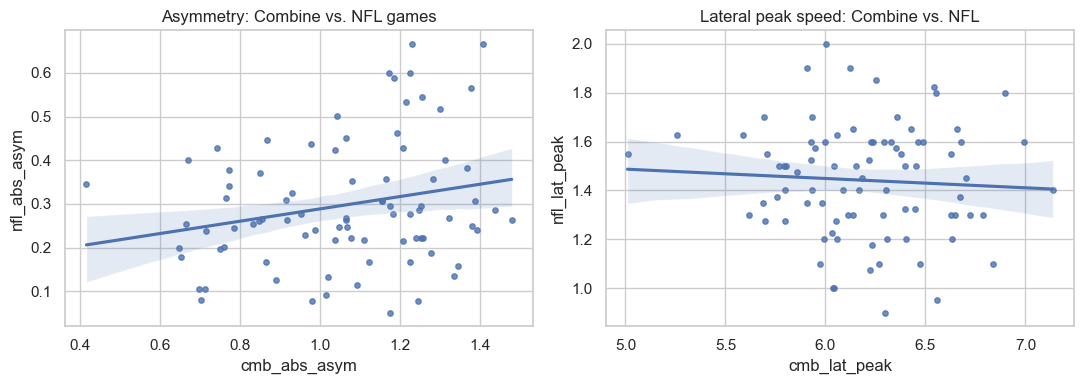

In [11]:
ct = pd.read_csv(find_csv("combine_tracking"), na_values=NULLS)
if "entity_type" in ct: ct = ct[ct["entity_type"] == "PLAYER"]
ct = ct[ct["nfl_id"].isin(ol["nfl_id"])].copy()
ct["time"] = pd.to_datetime(ct["time"], errors="coerce")
ct = ct.sort_values(["event_id", "nfl_id", "time"])

def combine_lateral(r):
    t = (r["time"] - r["time"].iloc[0]).dt.total_seconds().to_numpy()
    if len(t) < 8 or np.any(np.diff(t) <= 0): return None
    xy = np.c_[r["x"].to_numpy(float), r["y"].to_numpy(float)]; xy -= xy.mean(0)
    pos_ = xy @ np.linalg.svd(xy, full_matrices=False)[2][0]
    v = np.gradient(pos_, t); vs = v[np.abs(v) > .3]
    if len(vs) < 4 or (np.diff(np.sign(vs)) != 0).sum() < 1: return None
    a, b = v.max(), -v.min()
    return {"cmb_lat_peak": max(a, b), "cmb_abs_asym": abs(a - b) / ((a + b) / 2),
            "cmb_brake": np.nanmax(-np.gradient(v, t) * np.sign(v))}
rows = []
for (ev, nid), r in ct.groupby(["event_id", "nfl_id"], sort=False):
    q = combine_lateral(r)
    if q: rows.append({"nfl_id": nid, **q})
cmb_lat = pd.DataFrame(rows).groupby("nfl_id").mean() if rows else pd.DataFrame()
cmb_top = ct.groupby("nfl_id")["s"].max().rename("cmb_top_speed")       # fastest he moved at the Combine (any drill)
cmb = pd.concat([cmb_lat, cmb_top], axis=1)

nfl_lat = panel[panel["trk_reps"].notna()].groupby("nfl_id").agg(nfl_abs_asym=("abs_lr_asym", "median"),
                                                                  nfl_lat_peak=("lat_left", "median"))
both = cmb.join(nfl_lat, how="inner")
if len(both) >= 10 and "cmb_abs_asym" in both:
    r, p = stats.spearmanr(both["cmb_abs_asym"], both["nfl_abs_asym"], nan_policy="omit")
    r2, p2 = stats.spearmanr(both["cmb_lat_peak"], both["nfl_lat_peak"], nan_policy="omit")
    print(f"Combine → NFL asymmetry ρ = {r:.2f} (n={both[['cmb_abs_asym','nfl_abs_asym']].dropna().shape[0]}) | "
          f"Combine → NFL lateral peak speed ρ = {r2:.2f}")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.regplot(data=both, x="cmb_abs_asym", y="nfl_abs_asym", ax=axes[0], scatter_kws={"s": 15})
    sns.regplot(data=both, x="cmb_lat_peak", y="nfl_lat_peak", ax=axes[1], scatter_kws={"s": 15})
    axes[0].set_title("Asymmetry: Combine vs. NFL games"); axes[1].set_title("Lateral peak speed: Combine vs. NFL")
    plt.tight_layout(); plt.show()
else:
    print("Not enough overlap between Combine lateral drills and NFL tracking.")

## 9. Combine context: ceiling, utilization and capacity × load

These connect game movement back to the Combine:
- **Speed utilization** = his in-game peak speed (game p90) ÷ his fastest Combine speed. A player running near his ceiling every week has less in reserve.
- **Capacity × load**: is a spike in hard-braking load more dangerous for players with **low Combine capacity** (speed score, Combine braking)? Rates of next-game absence by load band are shown *within* Combine capacity terciles.

Median in-game speed utilization (p90 game speed ÷ Combine top speed): 0.43


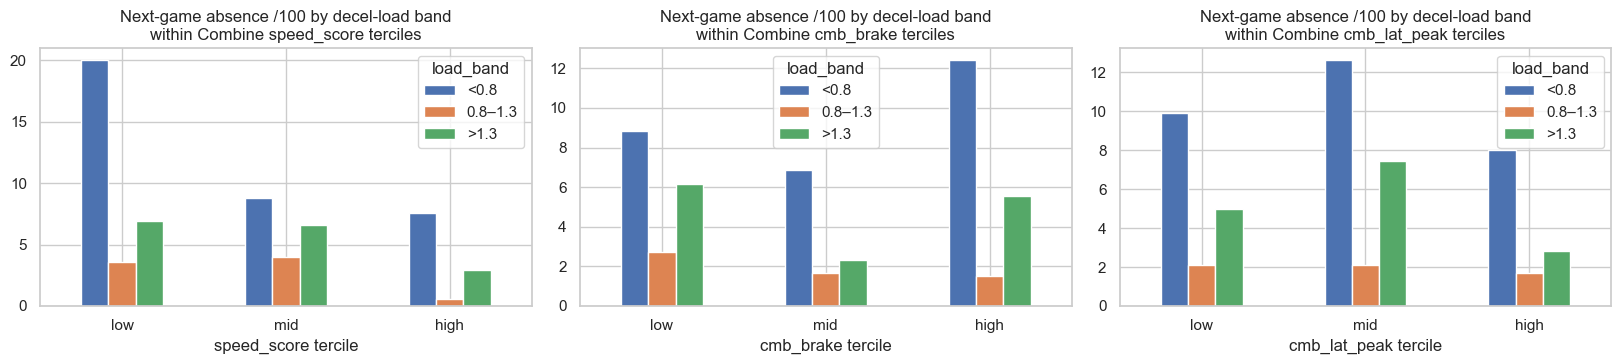

events  games  rate      capacity
cap_t load_band                                   
low   <0.8           12     60  20.0   speed_score
      0.8–1.3         3     84   3.6   speed_score
      >1.3            2     29   6.9   speed_score
mid   <0.8            8     91   8.8   speed_score
      0.8–1.3         4    100   4.0   speed_score
      >1.3            4     61   6.6   speed_score
high  <0.8            9    119   7.6   speed_score
      0.8–1.3         1    186   0.5   speed_score
      >1.3            2     69   2.9   speed_score
low   <0.8           10    113   8.8     cmb_brake
      0.8–1.3         4    148   2.7     cmb_brake
      >1.3            4     65   6.2     cmb_brake
mid   <0.8            5     73   6.8     cmb_brake
      0.8–1.3         2    119   1.7     cmb_brake
      >1.3            1     43   2.3     cmb_brake
high  <0.8           18    145  12.4     cmb_brake
      0.8–1.3         3    196   1.5     cmb_brake
      >1.3            5     90   5.6     cmb_brake
low   <0.8           11    111   9.9  cmb_lat_peak
      0.8–1.3         3    144   2.1  cmb_lat_peak
      >1.3            3     60   5.0  cmb_lat_peak
mid   <0.8           12     95  12.6  cmb_lat_peak
      0.8–1.3         3    142   2.1  cmb_lat_peak
      >1.3            5     67   7.5  cmb_lat_peak
high  <0.8           10    125   8.0  cmb_lat_peak
      0.8–1.3         3    177   1.7  cmb_lat_peak
      >1.3            2     71   2.8  cmb_lat_peak

In [12]:
p90 = rep.groupby(["game_id", "nfl_id"])["peak_speed"].quantile(.9).rename("game_p90_speed").reset_index()
panel = panel.drop(columns=[c for c in ["game_p90_speed", "speed_util"] if c in panel]).merge(p90, on=["game_id", "nfl_id"], how="left")
panel["speed_util"] = panel["game_p90_speed"] / panel["nfl_id"].map(cmb["cmb_top_speed"]) if "cmb_top_speed" in cmb else np.nan
util = panel.groupby("nfl_id")["speed_util"].median()
print("Median in-game speed utilization (p90 game speed ÷ Combine top speed):", round(util.median(), 2))

# Utilization z vs personal baseline → add to event-study style comparison at lag 1
v = panel["speed_util"]
mu = v.groupby(panel["nfl_id"]).transform(lambda s: s.shift().rolling(BASE_K, min_periods=BASE_MIN).mean())
sd = v.groupby(panel["nfl_id"]).transform(lambda s: s.shift().rolling(BASE_K, min_periods=BASE_MIN).std())
panel["z_speed_util"] = (v - mu) / sd

# Combine capacity features (player level)
W = pick(ol, ["combine_weight", "weight"])
if "forty" in ol and W: ol["speed_score"] = ol[W] * 200 / ol["forty"] ** 4
cap = ol.set_index("nfl_id")[[c for c in ["speed_score"] if c in ol]].join(cmb[[c for c in ["cmb_brake", "cmb_lat_peak"] if c in cmb]])

# Load ACWR from hard decels (acute = this game, chronic = mean of previous 4 tracked games)
hv = panel["hard_decels"]
chronic = hv.groupby(panel["nfl_id"]).transform(lambda s: s.shift().rolling(4, min_periods=3).mean())
panel["acwr_decel"] = hv / chronic
risk = panel[panel["played"] & panel["established"] & panel["acwr_decel"].notna()].copy()
risk["load_band"] = pd.cut(risk["acwr_decel"], [0, .8, 1.3, np.inf], labels=["<0.8", "0.8–1.3", ">1.3"])

fig, axes = plt.subplots(1, max(1, len(cap.columns)), figsize=(5.5 * max(1, len(cap.columns)), 3.8), squeeze=False)
capx = []
for ax, c in zip(axes.flat, cap.columns):
    t3 = pd.qcut(cap[c], 3, labels=["low", "mid", "high"], duplicates="drop") if cap[c].notna().sum() >= 9 else None
    if t3 is None: ax.axis("off"); continue
    d = risk.assign(cap_t=risk["nfl_id"].map(t3)).dropna(subset=["cap_t", "load_band"])
    tab = d.groupby(["cap_t", "load_band"], observed=True).agg(events=("next_absence", "sum"), games=("next_absence", "size"))
    tab["rate"] = 100 * tab["events"] / tab["games"]
    capx.append(tab.assign(capacity=c))
    tab["rate"].unstack().plot.bar(ax=ax, rot=0)
    ax.set_title(f"Next-game absence /100 by decel-load band\nwithin Combine {c} terciles"); ax.set_xlabel(f"{c} tercile")
plt.tight_layout(); plt.show()
if capx: display(pd.concat(capx).round(1))

## 10. Load revisited: movement-based acute:chronic ratios

This compares three load measures for the same outcome, next-game absence: snaps (playing time), yards moved, and hard decelerations (mechanical stress). If braking-based load separates better than snaps, the tracking data is adding something a box score can't.

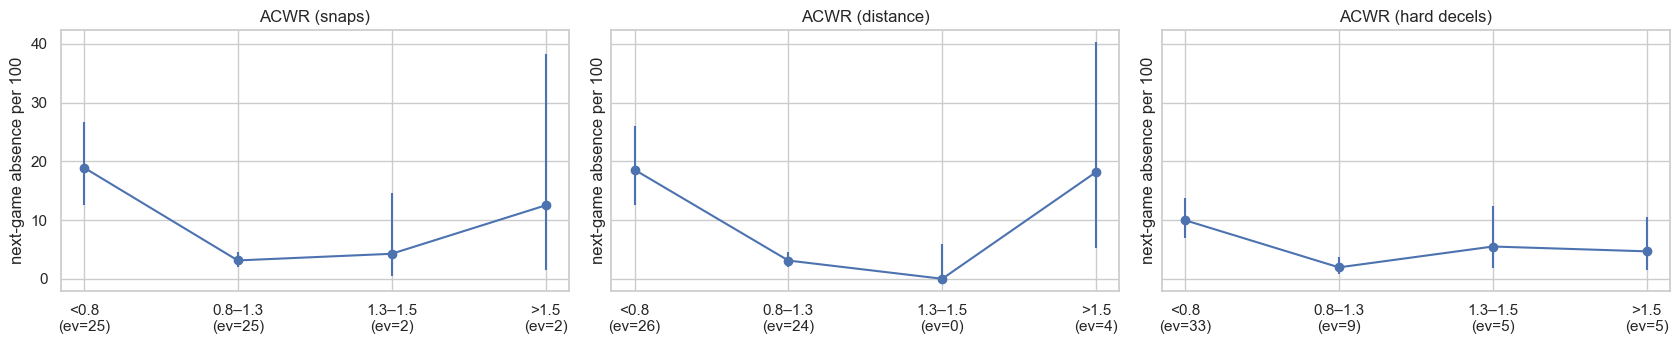

snaps                                 distance                                 hard decels                               
        events games players  rate    lo    hi   events games players  rate    lo    hi      events games players  rate   lo    hi
band                                                                                                                              
<0.8        25   132      50  18.9  12.6  26.7       26   140      51  18.6  12.5  26.0          33   331      59  10.0  7.0  13.7
0.8–1.3     25   800      60   3.1   2.0   4.6       24   773      60   3.1   2.0   4.6           9   463      55   1.9  0.9   3.7
1.3–1.5      2    47      32   4.3   0.5  14.5        0    60      39   0.0   0.0   6.0           5    91      40   5.5  1.8  12.4
>1.5         2    16      14  12.5   1.6  38.3        4    22      18  18.2   5.2  40.3           5   107      46   4.7  1.5  10.6

In [13]:
def acwr(col):
    v = panel[col].where(panel["trk_reps"].notna())
    ch = v.groupby(panel["nfl_id"]).transform(lambda s: s.shift().rolling(4, min_periods=3).mean())
    return v / ch
for c, name in [("trk_reps", "snaps"), ("dist_total", "distance"), ("hard_decels", "hard decels")]:
    panel[f"acwr_{name}"] = acwr(c)
at = panel[panel["played"] & panel["established"]]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)
acwr_tab = {}
for ax, name in zip(axes, ["snaps", "distance", "hard decels"]):
    d = at.dropna(subset=[f"acwr_{name}"]).copy()
    d["band"] = pd.cut(d[f"acwr_{name}"], [0, .8, 1.3, 1.5, np.inf], labels=["<0.8", "0.8–1.3", "1.3–1.5", ">1.5"])
    t = d.groupby("band", observed=True).agg(events=("next_absence", "sum"), games=("next_absence", "size"), players=("nfl_id", "nunique"))
    ci = [stats.binomtest(int(e), int(n)).proportion_ci() if n else (np.nan, np.nan) for e, n in zip(t["events"], t["games"])]
    t["rate"] = 100 * t["events"] / t["games"]; t["lo"] = [100 * c.low for c in ci]; t["hi"] = [100 * c.high for c in ci]
    acwr_tab[name] = t
    ax.errorbar(range(len(t)), t["rate"], yerr=[t["rate"] - t["lo"], t["hi"] - t["rate"]], fmt="o-")
    ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{b}\n(ev={e})" for b, e in zip(t.index, t["events"])])
    ax.set_title(f"ACWR ({name})"); ax.set_ylabel("next-game absence per 100")
plt.tight_layout(); plt.show()
display(pd.concat(acwr_tab, axis=1).round(1))

## 11. Single-feature screening: how well does each feature alone separate next-game absence?

Each game-level feature, raw and personal-z, gets an AUC for "absent next game" (and "long absence next game"), with player-clustered bootstrap CIs. AUC = 0.5 means no information. A feature whose CI excludes 0.5 **in both outcomes** is a candidate for the hazard model.

This doesn't use draft pick or any Combine variable, so the leak-free question is simply: *does this week's movement carry information about next week's availability?*

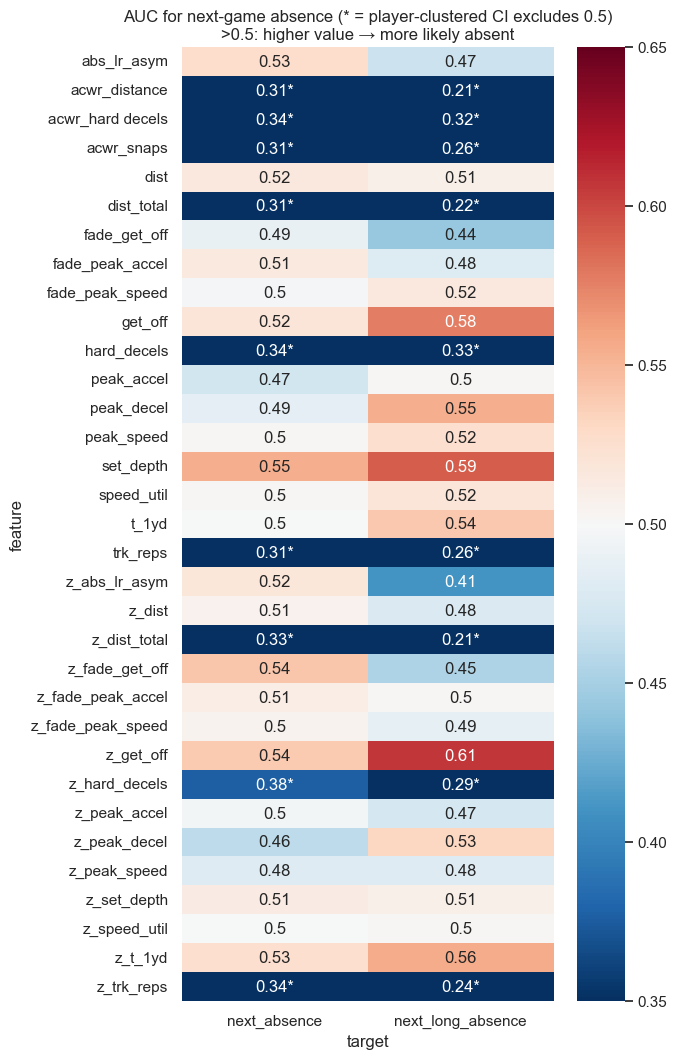

In [14]:
cand = [c for c in FEATS + ZF + ["speed_util", "z_speed_util", "acwr_snaps", "acwr_distance", "acwr_hard decels"] if c in panel]
base = panel[panel["played"] & panel["established"] & panel["trk_reps"].notna()].copy()
rows = []
for c in cand:
    for tgt in ["next_absence", "next_long_absence"]:
        a, lo, hi = cluster_boot_auc(base[tgt], base[c], base["nfl_id"])
        rows.append({"feature": c, "target": tgt, "auc": a, "ci_lo": lo, "ci_hi": hi,
                     "events": int(base.loc[base[c].notna(), tgt].sum())})
scr = pd.DataFrame(rows)
scr["dist_from_.5"] = (scr["auc"] - .5).abs()
scr["ci_excl_.5"] = (scr["ci_lo"] > .5) | (scr["ci_hi"] < .5)
wide = scr.pivot(index="feature", columns="target", values="auc")
plt.figure(figsize=(6, 0.33 * len(wide) + 1.5))
sig = scr.pivot(index="feature", columns="target", values="ci_excl_.5")
sns.heatmap(wide, annot=wide.round(2).astype(str) + np.where(sig.fillna(False), "*", ""), fmt="", cmap="RdBu_r", center=.5, vmin=.35, vmax=.65)
plt.title("AUC for next-game absence (* = player-clustered CI excludes 0.5)\n>0.5: higher value → more likely absent"); plt.show()

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

d = panel[panel["played"] & panel["established"] & ~panel["exit"]].copy()   # drop exit games (the artifact)
d["spike"] = (d["acwr_hard decels"] > 1.3).astype(float)
d["low_load"] = (d["acwr_snaps"] < 0.8).astype(float)
sets = {"snaps only": ["z_trk_reps", "low_load"],
        "+ get-off": ["z_trk_reps", "low_load", "z_get_off", "z_t_1yd"],
        "+ get-off + spike": ["z_trk_reps", "low_load", "z_get_off", "z_t_1yd", "spike"]}
for tgt in ["next_absence", "next_long_absence"]:
    for name, cols in sets.items():
        dd = d.dropna(subset=cols)
        y, X, grp = dd[tgt].astype(int).values, dd[cols].values, dd["nfl_id"].values
        pred = np.zeros(len(y))
        for tr, te in GroupKFold(5).split(X, y, grp):
            m = LogisticRegression(class_weight="balanced", max_iter=1000).fit(X[tr], y[tr])
            pred[te] = m.predict_proba(X[te])[:, 1]
        print(f"{tgt:18s} {name:20s} AUC={roc_auc_score(y, pred):.3f}  events={y.sum()}  games={len(y)}")

next_absence       snaps only           AUC=0.473  events=47  games=1027
next_absence       + get-off            AUC=0.496  events=47  games=1027
next_absence       + get-off + spike    AUC=0.507  events=47  games=1027
next_long_absence  snaps only           AUC=0.644  events=11  games=1027
next_long_absence  + get-off            AUC=0.667  events=11  games=1027
next_long_absence  + get-off + spike    AUC=0.619  events=11  games=1027


## 12. Synthesis

In [15]:
syn = []
l1 = event_stats[event_stats["lag"] == 1]
ctrl = l1[l1["set"] == "control"].set_index("feature")["mean_z"]
for _, r in l1[l1["set"] != "control"].iterrows():
    syn.append({"angle": f"5 pre-absence ({r['set']})", "feature": r["feature"].replace("z_", ""),
                "effect": r["mean_z"] - ctrl.get(r["feature"], 0), "unit": "z vs control at lag 1",
                "consistent_ci": (r["ci_lo"] > ctrl.get(r["feature"], 0)) or (r["ci_hi"] < ctrl.get(r["feature"], 0)), "n": r["n"]})
if len(ret):
    for _, r in ret_tab[ret_tab["spell"].astype(str).str.contains("long")].iterrows():
        syn.append({"angle": "7 return (long spells)", "feature": r["feature"], "effect": r["change_sd"], "unit": "SD change after return",
                    "consistent_ci": (r["ci_lo"] > 0) or (r["ci_hi"] < 0), "n": r["n"]})
for _, r in scr[scr["feature"].str.startswith("z_") & (scr["target"] == "next_absence")].iterrows():
    syn.append({"angle": "11 screening (z)", "feature": r["feature"].replace("z_", ""), "effect": r["auc"] - .5, "unit": "AUC − 0.5",
                "consistent_ci": r["ci_excl_.5"], "n": r["events"]})
syn = pd.DataFrame(syn)
hits = syn.groupby("feature").agg(angles_with_signal=("consistent_ci", "sum"), angles_tested=("angle", "nunique")).sort_values("angles_with_signal", ascending=False)
display(hits)
display(syn[syn["consistent_ci"]].sort_values("feature").round(3))

panel.to_csv("ol_tracking_absence_panel.csv", index=False)
rep.to_csv("ol_rep_mechanics.csv", index=False)
print("Saved ol_tracking_absence_panel.csv (player-game) and ol_rep_mechanics.csv (per rep)")

,angles_with_signal,angles_tested
feature,,
trk_reps,4,5
hard_decels,3,4
get_off,2,5
dist_total,1,1
fade_peak_speed,1,4
t_1yd,1,5
abs_lr_asym,0,4
dist,0,2
fade_get_off,0,1


,angle,feature,effect,unit,consistent_ci,n
50,11 screening (z),dist_total,-0.166,AUC − 0.5,True,68
19,5 pre-absence (exit→miss),fade_peak_speed,-2.652,z vs control at lag 1,True,4
0,5 pre-absence (absence),get_off,0.306,z vs control at lag 1,True,86
2,5 pre-absence (long absence),get_off,0.611,z vs control at lag 1,True,26
24,5 pre-absence (absence),hard_decels,-0.411,z vs control at lag 1,True,86
25,5 pre-absence (exit→miss),hard_decels,-1.931,z vs control at lag 1,True,21
49,11 screening (z),hard_decels,-0.124,AUC − 0.5,True,68
31,7 return (long spells),t_1yd,-0.604,SD change after return,True,11
28,5 pre-absence (exit→miss),trk_reps,-2.825,z vs control at lag 1,True,21
29,5 pre-absence (long absence),trk_reps,-1.521,z vs control at lag 1,True,26


Saved ol_tracking_absence_panel.csv (player-game) and ol_rep_mechanics.csv (per rep)


### How to use these results

- **The strongest evidence is agreement across angles.** For example: get-off slows in the games before long absences (§5), the last reps before an exit → miss degrade beyond normal fatigue (§6), *and* the player comes back slower after long spells (§7). That pattern is hard to produce with benching alone. The `hits` table counts this agreement.
- **§7 also tests the outcome proxy itself.** If nobody comes back diminished, even after 4+ game spells, then absences in this data are mostly roster decisions, and any injury model built on them is modeling coaching choices.
- **Reliability (§3) caps everything.** A mechanic with split-half reliability around 0.4 can't show a clean precursor effect even if one exists.

### The model this points to
A **discrete-time hazard model on the player-game panel**:
- outcome = absence (or long absence) next game
- features = this week's personal z-scores for the mechanics that survive here, movement-based load (ACWR of hard decels), within-game fade, and asymmetry
- Combine context as **interactions** (e.g. load × Combine braking capacity) rather than main effects
- a player random intercept, so stable differences between players are separated from week-to-week changes
- validation by **leaving whole players out** (grouped CV), because random game splits leak each player's baseline into the test set